# Ex08


Tự viết toàn bộ code. File này không có lời giải.

Làm lần lượt sáu phần:

1. Mã hóa (LabelEncoder và OneHotEncoder)
2. Ghép thành một bảng số duy nhất (concat)
3. Chuẩn hóa (StandardScaler hoặc MinMaxScaler)
4. Đưa bảng đã chuẩn hóa vào KMeans để gom cụm
5. Elbow để xem k
6. KNN để dự đoán Response

Dữ liệu: data/marketing_campaign.csv, dấu phân tách là tab.

Dùng đúng các cột sau, không thêm cột khác vào bảng đưa vào mô hình:

| Cột | Việc phải làm |
|---|---|
| Education | LabelEncoder |
| Marital_Status | OneHotEncoder |
| Income, Recency, MntWines, MntMeatProducts | giữ nguyên, vì đã là số |

Bỏ các dòng thiếu Income trước khi mã hóa. Không đưa Response vào bảng đặc trưng. Response chỉ dùng làm nhãn ở phần KNN.

random_state=0. Với KMeans đặt thêm n_init=10.


## 1. Mã hóa

Education và Marital_Status là chữ. KMeans không nhận chữ.

In classes_ của LabelEncoder sau khi fit. In tên cột do OneHotEncoder sinh ra.


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

df = pd.read_csv('marketing_campaign.csv',sep='\t')



In [28]:
df.columns = df.columns.str.strip()

In [29]:
df.columns.tolist()

['ID',
 'Year_Birth',
 'Education',
 'Marital_Status',
 'Income',
 'Kidhome',
 'Teenhome',
 'Dt_Customer',
 'Recency',
 'MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds',
 'NumDealsPurchases',
 'NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'Complain',
 'Z_CostContact',
 'Z_Revenue',
 'Response']

In [30]:
df = df.dropna(subset=['Income']).reset_index(drop=True)
len(df)

2216

In [41]:
le = LabelEncoder()
education_encoded = le.fit_transform(df['Education'])
le.classes_


ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
marital_encoded = ohe.fit_transform(df[['Marital_Status']])
marital_feature_names = ohe.get_feature_names_out(['Marital_Status'])
list(marital_feature_names)

['Marital_Status_Absurd',
 'Marital_Status_Alone',
 'Marital_Status_Divorced',
 'Marital_Status_Married',
 'Marital_Status_Single',
 'Marital_Status_Together',
 'Marital_Status_Widow',
 'Marital_Status_YOLO']

**Trả lời, không cần code.**

1. LabelEncoder xếp Education theo thứ tự nào? Thứ tự đó có phải Basic, rồi 2n Cycle, Graduation, Master, PhD hay không?
2. Vì sao Marital_Status dùng OneHotEncoder còn Education lại dùng LabelEncoder trong bài này?


In [ ]:
# LabelEncoder sắp xếp các giá trị theo thứ tự bảng chữ cái,thứ tự sắp xếp thực tế sẽ là: 2n Cycle, Basic, Graduation, Master, PhD
# Marital_Status là biến định danh dạng danh mục (nominal - không có thứ tự lớn nhỏ hơn kém giữa các trạng thái như Single, Married, Divorced...), nên việc dùng OneHotEncoder giúp tránh việc mô hình hiểu lầm là các trạng thái này có thứ tự giá trị số.

# Education trong phạm vi bài tập này được yêu cầu dùng LabelEncoder nhằm đơn giản hóa việc chuyển đổi chuỗi học vấn thành một cột số nguyên duy nhất.

## 2. Ghép thành một bảng số duy nhất

Ghép ba khối theo cột: số của Education, các cột biến giả của Marital_Status, và bốn cột số. Kết quả là một DataFrame, mọi cột đều là số, số dòng bằng số dòng sau khi bỏ Income thiếu.

In shape và columns.


In [42]:
df_education = pd.DataFrame(education_encoded, columns=['Education_Encoded'])
df_marital = pd.DataFrame(marital_encoded, columns=marital_feature_names)

num_cols = ['Income', 'Recency', 'MntWines', 'MntMeatProducts']
df_numeric = df[num_cols].reset_index(drop=True)

X_features = pd.concat([df_education, df_marital, df_numeric], axis=1)

In [43]:
X_features.shape

(2216, 13)

In [44]:
X_features.columns.tolist()

['Education_Encoded',
 'Marital_Status_Absurd',
 'Marital_Status_Alone',
 'Marital_Status_Divorced',
 'Marital_Status_Married',
 'Marital_Status_Single',
 'Marital_Status_Together',
 'Marital_Status_Widow',
 'Marital_Status_YOLO',
 'Income',
 'Recency',
 'MntWines',
 'MntMeatProducts']

**Trả lời.**

3. Bảng ghép có bao nhiêu dòng, bao nhiêu cột? Kể tên các cột biến giả.


In [ ]:
# có 2216 dòng và 13 cột 
# 'Education_Encoded',
#  'Marital_Status_Absurd',
#  'Marital_Status_Alone',
#  'Marital_Status_Divorced',
#  'Marital_Status_Married',
#  'Marital_Status_Single',
#  'Marital_Status_Together',
#  'Marital_Status_Widow',
#  'Marital_Status_YOLO',
#  'Income',
#  'Recency',
#  'MntWines',
#  'MntMeatProducts'

## 3. Chuẩn hóa

Chọn một trong hai: StandardScaler hoặc MinMaxScaler. Fit trên toàn bộ bảng vừa ghép. In trung bình mỗi cột sau khi scale, làm tròn 3 chữ số.


In [47]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

# In trung bình mỗi cột sau khi scale, làm tròn 3 chữ số
mean_values = np.round(np.mean(X_scaled, axis=0), 3)
for col, mean_val in zip(X_features.columns, mean_values):
    print(f"{col},{mean_val}")


Education_Encoded,0.0
Marital_Status_Absurd,-0.0
Marital_Status_Alone,0.0
Marital_Status_Divorced,-0.0
Marital_Status_Married,-0.0
Marital_Status_Single,-0.0
Marital_Status_Together,-0.0
Marital_Status_Widow,0.0
Marital_Status_YOLO,0.0
Income,0.0
Recency,-0.0
MntWines,-0.0
MntMeatProducts,-0.0


**Trả lời.**

4. Bạn chọn scaler nào? Income và MntWines sẽ chi phối khoảng cách thế nào nếu bỏ bước này?


In [ ]:
#Chọn StandardScaler
#Nếu bỏ qua bước chuẩn hóa, cột Income (có giá trị từ vài chục nghìn đến hàng trăm nghìn) và cột MntWines (có giá trị lên tới hàng nghìn) sẽ có độ lớn giá trị áp đảo hoàn toàn so với các biến còn lại

## 4. K-Means

n_clusters=3. In số dòng mỗi cụm và trung bình Income, Recency, MntWines, MntMeatProducts theo cụm. Trung bình tính trên giá trị gốc, không tính trên bảng đã scale.


In [50]:
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
df_original_subset = df[['Income', 'Recency', 'MntWines', 'MntMeatProducts']].copy()
df_original_subset['Cluster'] = cluster_labels
df_original_subset['Cluster'].value_counts().sort_index()

c:\Users\minht\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


Cluster
0    549
1    857
2    810
Name: count, dtype: int64

In [52]:
df_original_subset.groupby('Cluster').mean()

,Income,Recency,MntWines,MntMeatProducts
Cluster,,,,
0,51832.675774,49.158470,302.058288,185.380692
1,51724.978996,48.310385,299.855309,160.896149
2,53080.818519,49.656790,312.687654,160.988889


**Trả lời.**

5. Ba cụm khác nhau ở mức chi tiêu nào? Gọi tên mỗi cụm bằng chữ, không bằng id 0, 1, 2.
6. Đổi random_state thì id cụm có thể đảo. Cách đọc ở câu 5 còn đúng không?


In [ ]:
#5. Khác Chi tiêu dùng cao cấp khoảng 312.69, tiêu dùng thực phẩm khoảng 185.38

## 5. Elbow

Dùng đúng bảng đã chuẩn hóa ở phần 3. Thử k từ 1 đến 8. Với mỗi k, lưu inertia. Vẽ inertia theo k, trục hoành là k, trục tung là inertia.


c:\Users\minht\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\minht\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\minht\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\minht\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

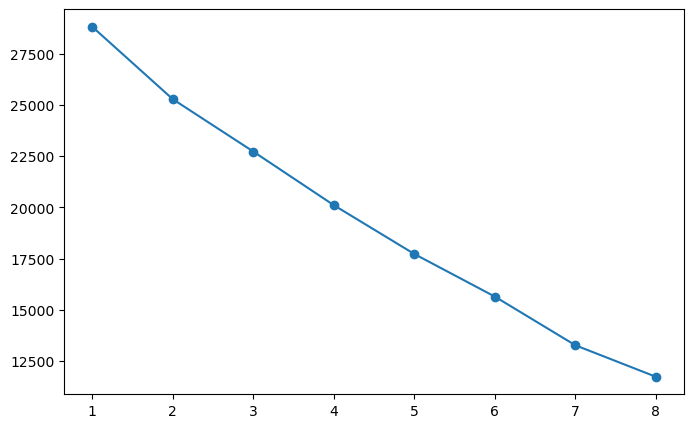

In [60]:
inertias = []
K_range = range(1, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o')
plt.show()


**Trả lời.**

7. Inertia nhỏ nhất trong bảng nằm ở k nào? Vì sao không chọn k đó làm số cụm?
8. Nhìn chỗ đường gãy, bạn chọn k nào cho phòng marketing? Có trùng k = 3 ở phần 4 không?


In [ ]:
#nertia nhỏ nhất nằm ở k = 8. Không chọn k này vì khi k quá lớn
#Chọn k = 4. Có thể trùng tùy theo độ gãy của biểu đồ

## 6. KNN

KNN không gom cụm. KNN cần nhãn. Nhãn là Response. Bảng đặc trưng là bảng đã ghép ở phần 2, bản chưa chuẩn hóa.

Chia train/test, test_size=0.2, random_state=0, stratify theo Response.

Tạo một scaler mới, cùng loại với phần 3. Fit scaler chỉ trên tập train, rồi transform tập test. Không dùng lại scaler đã fit trên toàn bộ dữ liệu ở phần 3.

Thử n_neighbors trong 1, 3, 5, 7, 11, 21. Với mỗi k in accuracy và F1 của lớp 1. Chọn một k và in classification_report của k đó.


In [62]:
X_knn = X_features.copy()
y_knn = df['Response'].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_knn, y_knn, test_size=0.2, random_state=0, stratify=y_knn
)

scaler_knn = StandardScaler()
X_train_scaled = scaler_knn.fit_transform(X_train)
X_test_scaled = scaler_knn.transform(X_test)

neighbor_list = [1, 3, 5, 7, 11, 21]
for k_val in neighbor_list:
    knn = KNeighborsClassifier(n_neighbors=k_val)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    f1_cls1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    print(f"k = {k_val:2d} | Accuracy: {acc:.4f} | F1-score (Lớp 1): {f1_cls1:.4f}")

k =  1 | Accuracy: 0.8153 | F1-score (Lớp 1): 0.3051
k =  3 | Accuracy: 0.8378 | F1-score (Lớp 1): 0.2800
k =  5 | Accuracy: 0.8491 | F1-score (Lớp 1): 0.2947
k =  7 | Accuracy: 0.8604 | F1-score (Lớp 1): 0.2955
k = 11 | Accuracy: 0.8671 | F1-score (Lớp 1): 0.2532
k = 21 | Accuracy: 0.8604 | F1-score (Lớp 1): 0.1622


In [65]:
chosen_k = 5
knn_final = KNeighborsClassifier(n_neighbors=chosen_k)
knn_final.fit(X_train_scaled, y_train)
y_pred_final = knn_final.predict(X_test_scaled)
print(classification_report(y_test, y_pred_final, zero_division=0))

              precision    recall  f1-score   support

           0       0.87      0.96      0.92       377
           1       0.50      0.21      0.29        67

    accuracy                           0.85       444
   macro avg       0.69      0.59      0.61       444
weighted avg       0.82      0.85      0.82       444



**Trả lời.**

9. stratify theo Response giữ điều gì giữa train và test?
10. Fit scaler trên cả bảng rồi mới chia train/test thì sai ở đâu?
11. k bạn chọn là bao nhiêu? Accuracy cao hơn F1 lớp 1 thì đọc thêm chỉ số nào trước khi kết luận mô hình tốt?
